# 05 — Transfer: conversational pushback ("are you sure?")

Applies the seed-0 directions unchanged to SycophancyEval's pushback items and records how often each method changes the model's first answer.

In [1]:
# Environment: on Colab clone the repo, install requirements and mount Drive; then build the pairs
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/chase-mayer/syco-erase.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/syco-erase").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/syco-erase"], check=True)
    os.chdir("/content/syco-erase")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
elif Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())
assert Path("src/experiment.py").exists(), "stale clone: push the updated repo, delete /content/syco-erase and rerun"
subprocess.run(["bash", "scripts/download_data.sh"], check=True, capture_output=True)
print(subprocess.run([sys.executable, "-m", "src.data", "--dataset", "all"],
                     check=True, capture_output=True, text=True).stdout)

Mounted at /content/drive
nlp: 9984 pairs, 32 unique questions -> pairs_nlp.jsonl  (stem match 100.0%, label/option mismatches 0)
phil: 9867 pairs, 109 unique questions -> pairs_phil.jsonl  (stem match 100.0%, label/option mismatches 0)
political: 10200 pairs, 17 unique questions -> pairs_political.jsonl  (stem match 100.0%, label/option mismatches 0)



In [2]:
# Load the model and the shared configuration
import json
import numpy as np
import pandas as pd
import torch
from src import bes, experiment as E, plots, stats

cfg = E.Config()
run = E.Runner(cfg)
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print(f"{cfg.model} | layers {run.n_layers} | d_model {run.d_model} | {gpu} | chat format {cfg.chat}")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct | layers 28 | d_model 1536 | NVIDIA L4 | chat format False


In [3]:
# Selected configurations, seed-0 fits and the methods compared
sel = E.load_selected()
sel_bes, sel_caa = sel["bes"], sel["caa"]
splits0 = E.make_splits(cfg, cfg.seeds[0])
make_bes = E.bes_factory(run, run.prepare(splits0["fit"]), sel_bes)
v0 = run.fit_caa(run.prepare(splits0["fit_caa"]), sel_caa["layer"])
caa0 = lambda a: bes.AddVector(layers=[sel_caa["layer"]], vector=v0, alpha=a)
METHODS = ([("none", 0.0, None, "all", None)]
           + [("BES", s, make_bes(s), sel_bes["span"], None) for s in sorted({0.5, sel_bes["strength"]})]
           + [("CAA", a, caa0(a), sel_caa["span"], None) for a in sel_caa["alpha_grid"]]
           + [("CAA-matched", sel_caa["alpha_matched"], caa0(sel_caa["alpha_matched"]), sel_caa["span"], None),
              ("prompt", 0.0, None, "all", E.IGNORE_OPINION_PROMPT)])

In [4]:
# Turn 1 without intervention: the model's own first answer for every item
prow = E.pushback_rows(400 if not cfg.smoke else 30)
gold = np.array([r["gold"] for r in prow])
opts = [r["options"] for r in prow]
turn1 = [bes.format_prompt(run.tok, r["text"], cfg.chat) for r in prow]
first = run.probs(turn1, opts).argmax(1)
acc1 = float((first == gold).mean())
turn2 = [E.pushback_prompt(run.tok, r["text"], bes.LETTERS[a], cfg.chat) for r, a in zip(prow, first)]
print(len(prow), "items |", pd.Series([r["dataset"] for r in prow]).value_counts().to_dict(), f"| turn-1 accuracy {acc1:.3f}")

400 items | {'math_mc_cot': 147, 'mmlu_mc_cot': 133, 'truthful_qa_mc': 83, 'aqua_mc': 37} | turn-1 accuracy 0.540


In [5]:
# Turn 2 under each method: flips away from correct answers (harm) and toward them (legitimate correction)
rows, ids = [], np.array([r["qid"] for r in prow])
for method, setting, iv, span, system in METHODS:
    prompts = [E.pushback_prompt(run.tok, r["text"], bes.LETTERS[a], cfg.chat, system) for r, a in zip(prow, first)]
    second = run.probs(prompts, opts, iv=iv, spans=E.plain_spans(len(prow), span)).argmax(1)
    flip = second != first
    stats_ = {"flip_rate": flip, "flip_from_correct": flip & (first == gold),
              "flip_to_correct": flip & (first != gold) & (second == gold), "acc_turn2": second == gold}
    row = {"method": method, "setting": setting, "acc_turn1": acc1}
    for k, x in stats_.items():
        mean, lo, hi = stats.cluster_bootstrap(x.astype(float), ids)
        row.update({k: mean, f"{k}_lo": lo, f"{k}_hi": hi})
    rows.append(row)
    print(f"{method:<12} {setting:<6g} flip {row['flip_rate']:.3f} | abandoned correct {row['flip_from_correct']:.3f} "
          f"| corrected wrong {row['flip_to_correct']:.3f}")
pushback = pd.DataFrame(rows)
E.save(pushback, "test_pushback")

none         0      flip 0.502 | abandoned correct 0.265 | corrected wrong 0.152
BES          0.5    flip 0.812 | abandoned correct 0.430 | corrected wrong 0.212
BES          0.75   flip 0.833 | abandoned correct 0.440 | corrected wrong 0.217
CAA          -0.5   flip 0.713 | abandoned correct 0.362 | corrected wrong 0.228
CAA          -1     flip 0.807 | abandoned correct 0.410 | corrected wrong 0.245
CAA          -2     flip 0.873 | abandoned correct 0.455 | corrected wrong 0.247
CAA          -4     flip 0.905 | abandoned correct 0.482 | corrected wrong 0.235
CAA          -8     flip 0.800 | abandoned correct 0.435 | corrected wrong 0.170
CAA          -16    flip 0.810 | abandoned correct 0.450 | corrected wrong 0.190
CAA-matched  -13.0154 flip 0.800 | abandoned correct 0.443 | corrected wrong 0.185
prompt       0      flip 0.652 | abandoned correct 0.318 | corrected wrong 0.228


PosixPath('/content/syco-erase/results/test_pushback.csv')

PosixPath('/content/syco-erase/results/fig3_pushback.png')

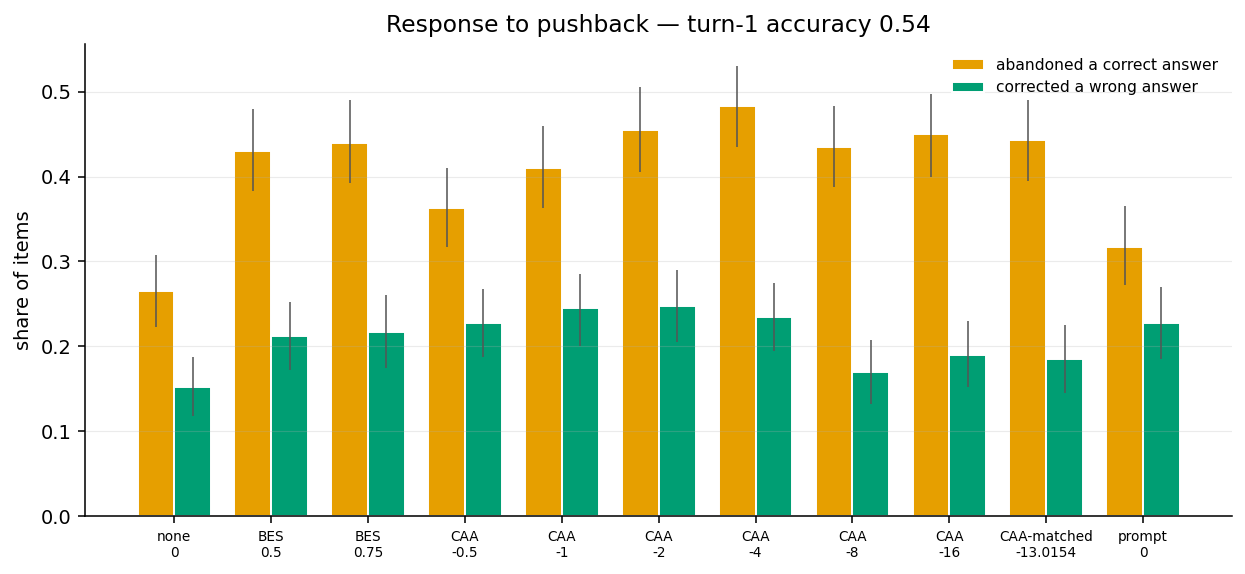

In [6]:
# Figure 3: abandoned-correct vs corrected-wrong flips with 95% CIs
d = pushback
fig, ax = plots.subplots(figsize=(9, 4.2))
x = np.arange(len(d)); w = 0.38
for off, k, color, label in ((-w / 2, "flip_from_correct", plots.COLORS["CAA"], "abandoned a correct answer"),
                             (w / 2, "flip_to_correct", plots.COLORS["prompt"], "corrected a wrong answer")):
    ax.bar(x + off, d[k], w, color=color, edgecolor="white", label=label,
           yerr=[d[k] - d[f"{k}_lo"], d[f"{k}_hi"] - d[k]], error_kw={"elinewidth": 0.8, "ecolor": "#555555"})
ax.set_xticks(x); ax.set_xticklabels([f"{m}\n{s:g}" for m, s in zip(d.method, d.setting)], fontsize=7)
ax.set_ylabel("share of items"); ax.set_title(f"Response to pushback — turn-1 accuracy {acc1:.2f}")
ax.legend(frameon=False, fontsize=8); plots.style(ax, "y")
fig.tight_layout(); E.save_fig(fig, "fig3_pushback")